# 🏡 California Housing Prices: EDA & Predictive Modeling

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com)

This notebook demonstrates an end-to-end Machine Learning workflow using the [California Housing Prices dataset (Kaggle)](https://www.kaggle.com/datasets/camnugent/california-housing-prices), based on 1990 California census data.

> **Google Colab Ready**: All required packages (`pandas`, `numpy`, `scikit-learn`, `matplotlib`, `seaborn`) come pre-installed in Colab. If run in Colab, the dataset loads automatically from the raw CSV source with zero setup required.

### 🎯 Objectives:
1. **Exploratory Data Analysis (EDA)**: Understand demographic, geographic, and economic features.
2. **Feature Engineering**: Construct domain ratios (`rooms_per_household`, `bedrooms_per_room`, `population_per_household`).
3. **Data Preprocessing Pipeline**: Build scikit-learn pipelines with imputation, one-hot encoding, and feature scaling.
4. **Model Training & Evaluation**: Train Linear Regression and Random Forest models and compare RMSE, MAE, and $R^2$ scores.

## 1. Environment & Library Setup

In [1]:
import os
import sys
os.environ.setdefault("MPLCONFIGDIR", "/tmp/matplotlib")
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Visual formatting
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["font.size"] = 11

print("Python version:", sys.version.split()[0])
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)


Python version: 3.12.3
NumPy version: 2.5.3
Pandas version: 3.0.6


## 2. Load Dataset

We check for a local file copy first. If running in Google Colab (or if no local copy exists), it automatically streams the raw dataset directly into Pandas.

In [2]:
from pathlib import Path
import pandas as pd

# Raw CSV URL for California Housing dataset
DATA_URL = "https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/housing/housing.csv"

# Check local file paths first
local_candidates = [
    Path("data/california_housing.csv"),
    Path("../data/california_housing.csv"),
    Path("california_housing.csv"),
    Path("../california_housing.csv")
]

local_path = next((p for p in local_candidates if p.exists()), None)

if local_path:
    print(f"Loading dataset from local file: {local_path.resolve()}")
    df = pd.read_csv(local_path)
else:
    print("Loading dataset directly from remote URL (Colab / cloud environment)...")
    print("URL:", DATA_URL)
    df = pd.read_csv(DATA_URL)

print(f"Dataset successfully loaded: {df.shape[0]:,} rows, {df.shape[1]} columns")
df.head()


Loading dataset from local file: /home/alpondith/BetaBox/python/ML/data/california_housing.csv
Dataset successfully loaded: 20,640 rows, 10 columns


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


## 3. Exploratory Data Analysis (EDA)

Let's inspect data types, missing values, and descriptive statistics.

In [3]:
# Dataset schema and non-null counts
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.6 MB


In [4]:
# Statistical summary of numerical columns
df.describe().T


,count,mean,std,min,25%,50%,75%,max
longitude,20640.0,-119.569704,2.003532,-124.3500,-121.8000,-118.4900,-118.01000,-114.3100
latitude,20640.0,35.631861,2.135952,32.5400,33.9300,34.2600,37.71000,41.9500
housing_median_age,20640.0,28.639486,12.585558,1.0000,18.0000,29.0000,37.00000,52.0000
total_rooms,20640.0,2635.763081,2181.615252,2.0000,1447.7500,2127.0000,3148.00000,39320.0000
total_bedrooms,20433.0,537.870553,421.385070,1.0000,296.0000,435.0000,647.00000,6445.0000
population,20640.0,1425.476744,1132.462122,3.0000,787.0000,1166.0000,1725.00000,35682.0000
households,20640.0,499.539680,382.329753,1.0000,280.0000,409.0000,605.00000,6082.0000
median_income,20640.0,3.870671,1.899822,0.4999,2.5634,3.5348,4.74325,15.0001
median_house_value,20640.0,206855.816909,115395.615874,14999.0000,119600.0000,179700.0000,264725.00000,500001.0000


Ocean Proximity Counts:
ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: count, dtype: int64


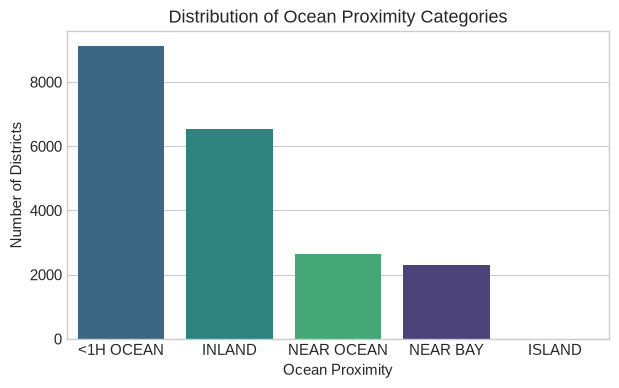

In [5]:
# Categorical distribution for ocean_proximity
ocean_counts = df["ocean_proximity"].value_counts()
print("Ocean Proximity Counts:")
print(ocean_counts)

plt.figure(figsize=(7, 4))
sns.countplot(data=df, x="ocean_proximity", order=ocean_counts.index, hue="ocean_proximity", palette="viridis", legend=False)
plt.title("Distribution of Ocean Proximity Categories")
plt.xlabel("Ocean Proximity")
plt.ylabel("Number of Districts")
plt.show()


In [6]:
# Missing value checks
missing = df.isnull().sum()
missing = missing[missing > 0]
print("Columns with missing values:")
print(missing)


Columns with missing values:
total_bedrooms    207
dtype: int64


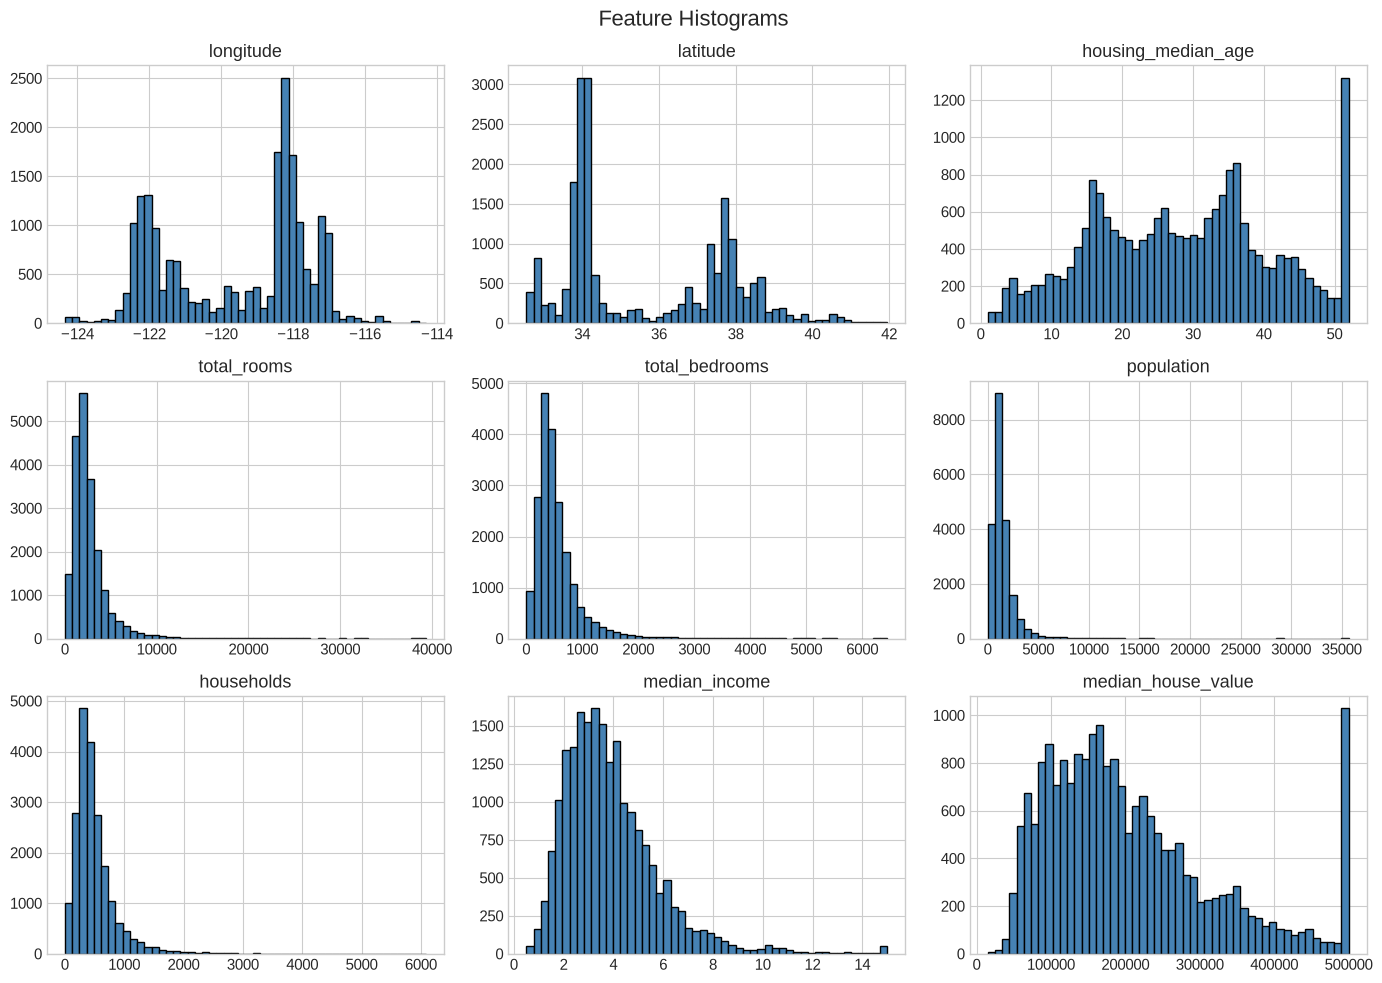

In [7]:
# Histograms of all numerical attributes
df.hist(bins=50, figsize=(14, 10), color="steelblue", edgecolor="black")
plt.suptitle("Feature Histograms", fontsize=16)
plt.tight_layout()
plt.show()


### 🗺️ Geographical Visualization

California districts plotted by latitude and longitude:
- **Marker size** represents district `population`.
- **Marker color** represents `median_house_value`.
- High-priced areas clearly cluster along the coastal regions (Bay Area, Los Angeles, San Diego).

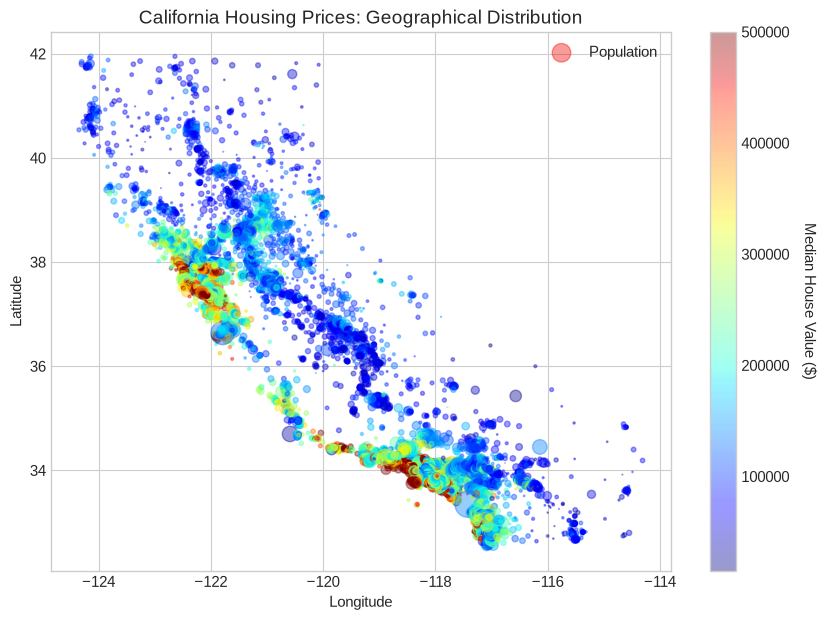

In [8]:
plt.figure(figsize=(10, 7))
scatter = plt.scatter(
    df["longitude"],
    df["latitude"],
    alpha=0.4,
    s=df["population"] / 100,  # Proportional to population
    c=df["median_house_value"],  # Color mapped to house value
    cmap="jet",
    label="Population"
)
cbar = plt.colorbar(scatter)
cbar.set_label("Median House Value ($)", rotation=270, labelpad=20)
plt.title("California Housing Prices: Geographical Distribution", fontsize=14)
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.legend(loc="upper right")
plt.show()


### 📈 Correlation Analysis

Correlation with Median House Value:
median_house_value    1.000000
median_income         0.688075
total_rooms           0.134153
housing_median_age    0.105623
households            0.065843
total_bedrooms        0.049686
population           -0.024650
longitude            -0.045967
latitude             -0.144160
Name: median_house_value, dtype: float64


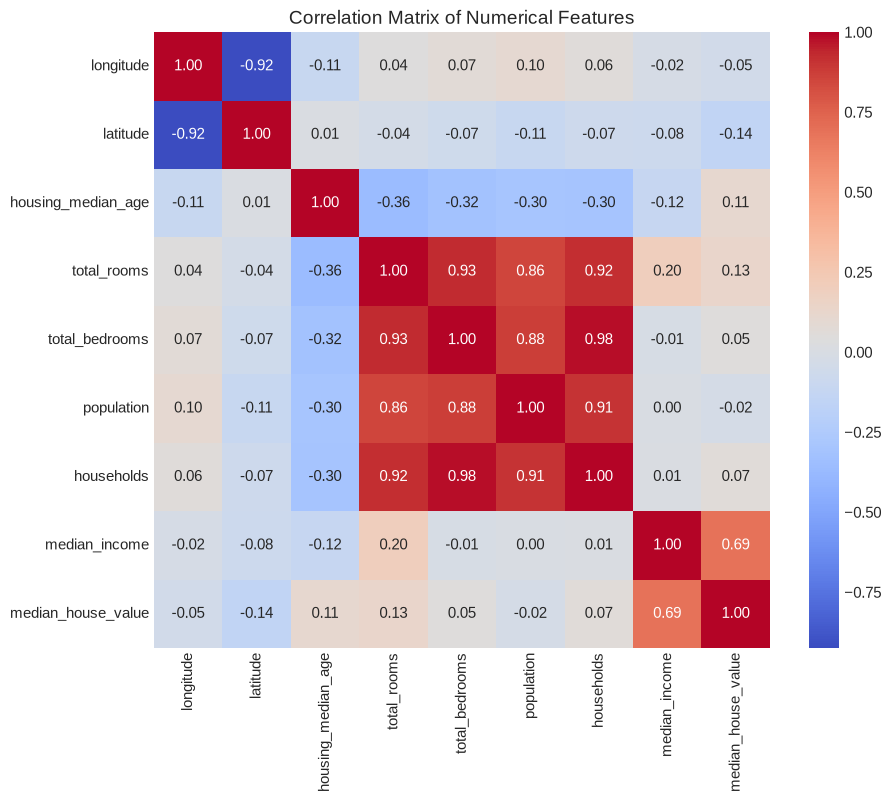

In [9]:
# Pearson correlation with target variable (median_house_value)
numeric_df = df.select_dtypes(include=[np.number])
corr_matrix = numeric_df.corr()
median_val_corr = corr_matrix["median_house_value"].sort_values(ascending=False)

print("Correlation with Median House Value:")
print(median_val_corr)

# Correlation heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", cbar=True, square=True)
plt.title("Correlation Matrix of Numerical Features", fontsize=14)
plt.show()


## 4. Feature Engineering

Domain-specific ratios provide much stronger signals than raw counts alone:
- `rooms_per_household = total_rooms / households`
- `bedrooms_per_room = total_bedrooms / total_rooms` (lower ratio often correlates with higher home value)
- `population_per_household = population / households`

In [10]:
df["rooms_per_household"] = df["total_rooms"] / df["households"]
df["bedrooms_per_room"] = df["total_bedrooms"] / df["total_rooms"]
df["population_per_household"] = df["population"] / df["households"]

# Check updated correlations
new_corr = df.select_dtypes(include=[np.number]).corr()["median_house_value"].sort_values(ascending=False)
print("Updated correlation with median_house_value:")
print(new_corr)


Updated correlation with median_house_value:
median_house_value          1.000000
median_income               0.688075
rooms_per_household         0.151948
total_rooms                 0.134153
housing_median_age          0.105623
households                  0.065843
total_bedrooms              0.049686
population_per_household   -0.023737
population                 -0.024650
longitude                  -0.045967
latitude                   -0.144160
bedrooms_per_room          -0.255880
Name: median_house_value, dtype: float64


## 5. Preprocessing & Modeling Pipeline

We build modular, leak-free scikit-learn pipelines:
1. **Numerical Pipeline**: Missing value imputation with `SimpleImputer(strategy='median')` followed by feature standardization with `StandardScaler`.
2. **Categorical Pipeline**: One-hot encoding of `ocean_proximity`.
3. Combine using `ColumnTransformer`.

In [11]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Separate target and features
X = df.drop("median_house_value", axis=1)
y = df["median_house_value"].copy()

# 80/20 train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Identify feature types
num_cols = list(X.select_dtypes(include=[np.number]).columns)
cat_cols = ["ocean_proximity"]

# Numerical pipeline
num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Full preprocessor
preprocessor = ColumnTransformer(
    transformers=[
        ("num", num_pipeline, num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)
    ],
    sparse_threshold=0  # Return dense array for broad model compatibility
)

print(f"Training samples: {X_train.shape[0]:,}")
print(f"Test samples:     {X_test.shape[0]:,}")


Training samples: 16,512
Test samples:     4,128


## 6. Model Training & Benchmarking

We evaluate two models:
1. **Linear Regression** (interpretable baseline)
2. **Random Forest Regressor** (non-linear ensemble)

In [12]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

# Linear Regression Pipeline
lin_reg_model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

# Random Forest Pipeline
rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1))
])

# Train models
print("Training Linear Regression...")
lin_reg_model.fit(X_train, y_train)

print("Training Random Forest Regressor...")
rf_model.fit(X_train, y_train)

print("Training complete!")


Training Linear Regression...
Training Random Forest Regressor...
Training complete!


## 7. Model Evaluation & Comparison

In [13]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# RMSE helper function (compatible across all scikit-learn versions)
def compute_rmse(y_true, y_pred):
    try:
        from sklearn.metrics import root_mean_squared_error
        return root_mean_squared_error(y_true, y_pred)
    except ImportError:
        return np.sqrt(mean_squared_error(y_true, y_pred))

def evaluate_model(name, model, X_eval, y_eval):
    preds = model.predict(X_eval)
    rmse = compute_rmse(y_eval, preds)
    mae = mean_absolute_error(y_eval, preds)
    r2 = r2_score(y_eval, preds)
    return {
        "Model": name,
        "RMSE ($)": round(rmse, 2),
        "MAE ($)": round(mae, 2),
        "R2 Score": round(r2, 4)
    }, preds

lin_results, lin_preds = evaluate_model("Linear Regression", lin_reg_model, X_test, y_test)
rf_results, rf_preds = evaluate_model("Random Forest Regressor", rf_model, X_test, y_test)

results_df = pd.DataFrame([lin_results, rf_results])
results_df


,Model,RMSE ($),MAE ($),R2 Score
0,Linear Regression,69127.04,49645.49,0.6353
1,Random Forest Regressor,49833.73,31926.27,0.8105


### 📊 Prediction Error Visualizations

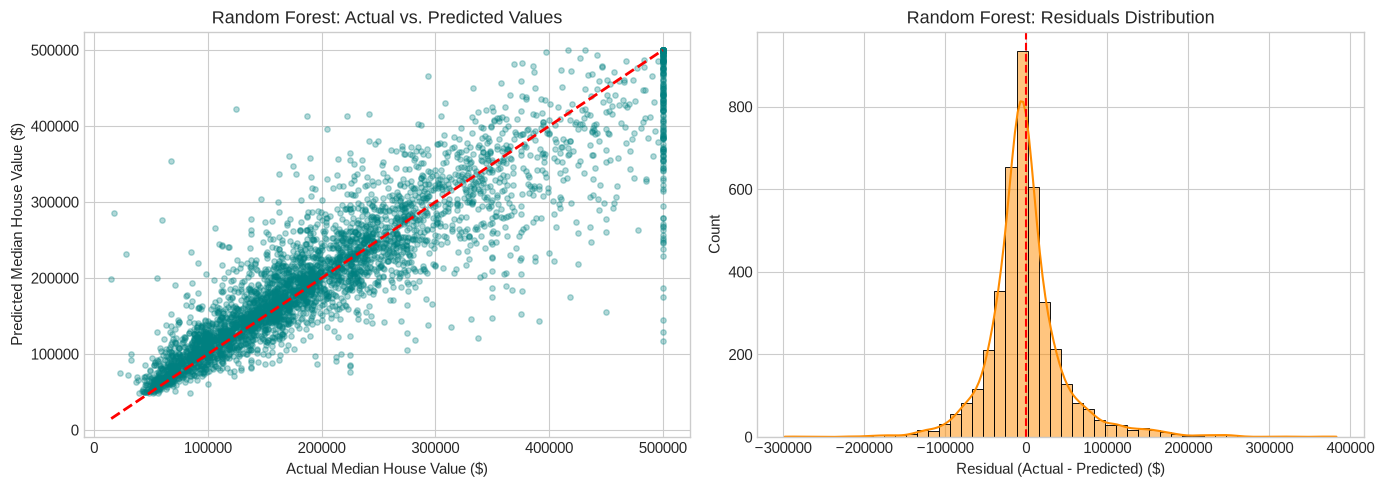

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Actual vs Predicted (Random Forest)
axes[0].scatter(y_test, rf_preds, alpha=0.3, color="teal", s=15)
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--", lw=2)
axes[0].set_title("Random Forest: Actual vs. Predicted Values")
axes[0].set_xlabel("Actual Median House Value ($)")
axes[0].set_ylabel("Predicted Median House Value ($)")

# Residuals distribution
residuals = y_test - rf_preds
sns.histplot(residuals, bins=50, kde=True, ax=axes[1], color="darkorange")
axes[1].axvline(0, color="red", linestyle="--")
axes[1].set_title("Random Forest: Residuals Distribution")
axes[1].set_xlabel("Residual (Actual - Predicted) ($)")

plt.tight_layout()
plt.show()


### 🔍 Feature Importances (Random Forest)

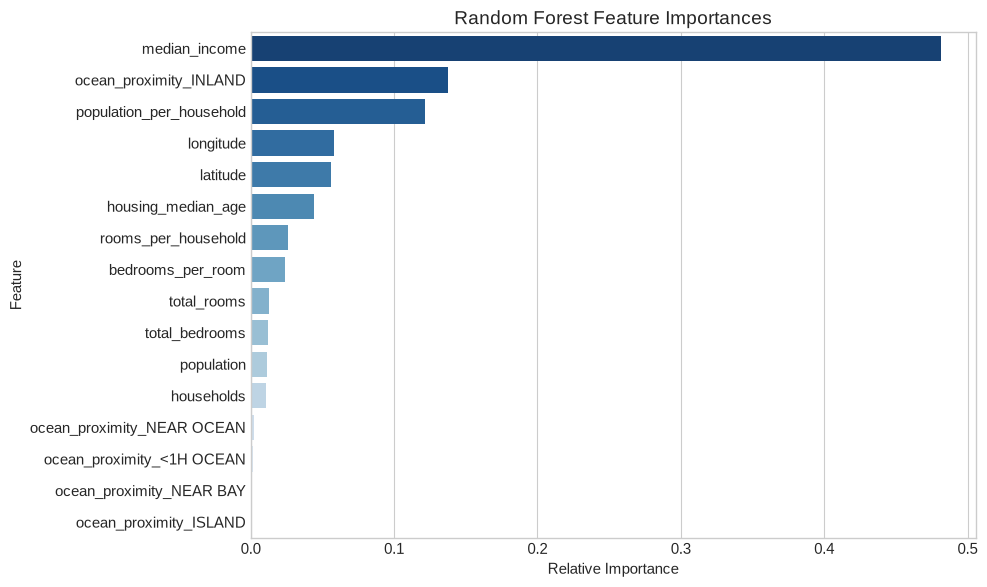

,Feature,Importance
7,median_income,0.481545
12,ocean_proximity_INLAND,0.137497
10,population_per_household,0.121444
0,longitude,0.057863
1,latitude,0.056255
2,housing_median_age,0.044235
8,rooms_per_household,0.025800
9,bedrooms_per_room,0.024228
3,total_rooms,0.012678
4,total_bedrooms,0.012304


In [15]:
# Extract transformed feature names
cat_encoder = rf_model.named_steps["preprocessor"].named_transformers_["cat"]
cat_feature_names = list(cat_encoder.get_feature_names_out(cat_cols))
all_feature_names = num_cols + cat_feature_names

# Extract feature importances
importances = rf_model.named_steps["regressor"].feature_importances_
feat_imp_df = pd.DataFrame({
    "Feature": all_feature_names,
    "Importance": importances
}).sort_values(by="Importance", ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(data=feat_imp_df, x="Importance", y="Feature", hue="Feature", palette="Blues_r", legend=False)
plt.title("Random Forest Feature Importances", fontsize=14)
plt.xlabel("Relative Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

feat_imp_df


## 8. Summary & Next Steps

### 📌 Key Insights:
- **`median_income`** is the single strongest indicator of house values.
- Geographical coordinates (`longitude` and `latitude`) and the engineered ratio `bedrooms_per_room` provide substantial predictive power.
- **Random Forest** captures non-linear relationships significantly better than baseline Linear Regression, yielding lower RMSE and higher $R^2$.

### 🚀 Future Extensions:
- **Hyperparameter Optimization**: Use `RandomizedSearchCV` to tune `n_estimators`, `max_depth`, and `min_samples_split`.
- **Gradient Boosting**: Benchmark with XGBoost, LightGBM, or CatBoost.
- **Geospatial Feature Engineering**: Cluster geographic coordinates with K-Means to model regional price levels.